In [313]:
# Messung capillary / Messung mittels Bypass
# Messtag 19.05.2026

# theoretische configuration
# 250 nml-min Reaktor
# 0 nml-min Matrix
# 2 bar abs
# 25 °C

# praktische Werte (anpassung da MS messung nur 1 bar möchlich)
# 125 nml-min Reaktor
# 0 nml-min Matrix
# 1 bar abs
# 25 °C

In [314]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import ICIW_Plots

plt.style.use("ICIWstyle")
plt.rcParams["font.size"] = 7

In [315]:
n_dot_old = np.load(r"C:\Users\admin\iCloudDrive\03 - Universität Master\Research Internship\Python\AZA_001\nRTD-AZA_FBA_THA\Experiments\HSA_004\data\FBA-E-19032025_250ml-min_2bar_250_TotalSystem_composition.npy")
timestamps = np.load(r"C:\Users\admin\iCloudDrive\03 - Universität Master\Research Internship\Python\AZA_001\nRTD-AZA_FBA_THA\Experiments\HSA_004\data\FBA-E-19032025_250ml-min_2bar_250_TotalSystem_times.npy")

n_dot = np.load(r"C:\Users\admin\Nextcloud\RI Herrmann\3_Experiments\THB_V4_vorreactor_varVdot\results\data_ptk_capillary_nocat_25°C_aequi_2bar_reactor63mlmin_matrix0mlmin.npz")['n_dot'].T[:,[0, 1, 2]]
t_source = np.load(r"C:\Users\admin\Nextcloud\RI Herrmann\3_Experiments\THB_V4_vorreactor_varVdot\results\data_ptk_capillary_nocat_25°C_aequi_2bar_reactor63mlmin_matrix0mlmin.npz")['time_delta']

In [316]:
print("n_dot_old shape",n_dot_old.shape)
print("n_dot shape",n_dot.shape)

print("timestamps shape",timestamps.shape)
print("t_source shape",t_source.shape)

n_dot_old shape (149166, 3)
n_dot shape (29044, 3)
timestamps shape (149166,)
t_source shape (29044,)


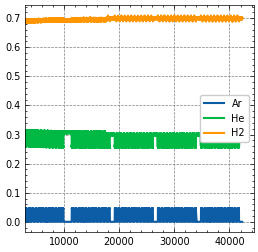

In [317]:
plt.plot(timestamps, n_dot_old[:,0], label="Ar", color="C0")
plt.plot(timestamps, n_dot_old[:,1], label="He", color="C1")
plt.plot(timestamps, n_dot_old[:,2], label="H2", color="C2")
plt.xlim(20.25 + 45 * 60 + 5 * 60,)
plt.legend()

13785.857


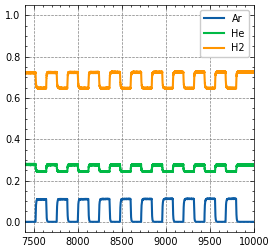

In [318]:
plt.plot(t_source, n_dot[:,0], label="Ar", color="C0")
plt.plot(t_source, n_dot[:,1], label="He", color="C1")
plt.plot(t_source, n_dot[:,2], label="H2", color="C2")
plt.xlim(7400, 10000)
#plt.xlim(0,300)
# plt.scatter(15*60, 0.2)
# plt.xlim(14*60, 16*60)
#plt.xlim(14.5*60,)
plt.legend()

print(t_source[-1])


In [319]:
time_delta = t_source - t_source[0]

np.savez(
    "nRTD_ptk_capillary_nocat_25°C_1bar_reactor63mlmin_matrix0mlmin.npz",
    n_dot=n_dot.T,
    time_delta=time_delta,
)

t_range = (time_delta.min(), time_delta.max())

In [320]:
# create array with half-period times

t_out = (0.0, 120.0)
n_out = int(4 * (t_out[1] - t_out[0]) + 1)
delta_t_out = (t_out[1] - t_out[0]) / (n_out - 1)
t_offset = 12900 # offset until experiment starts
t_halfperiod = 120 # 2min half-period duration
t_kernel = (0, 35)
n_kernel = int(((t_kernel[1] - t_kernel[0]) / delta_t_out) + 1)
t_in = (0, t_out[1] - t_kernel[1])
n_in = int(((t_in[1] - t_in[0]) / delta_t_out) + 1)

switching_times = np.full((10,), t_halfperiod) + np.array([-0.03,
                                                          -0.06,
                                                          0.02,
                                                          0.07,
                                                          -0.21,
                                                          0.16,
                                                          -0.03,
                                                          -0.01,
                                                          -0.03,
                                                          0.14])
print(switching_times)

t_offset = t_source[-1] - sum(switching_times)
print(t_offset)
switching_times = np.insert(switching_times, 0, t_offset)
switching_times = np.cumsum(switching_times)
print(switching_times)

intervals = [
    (switching_times[i], switching_times[i + 1])
    for i in range(len(switching_times) - 1)
]
print(intervals)



print("t_in",t_in)
print("t_in[0]",t_in[0])
print("t_out[1]",t_out[1])
print("n_in",n_in)
print("n_out",n_out)

[119.97 119.94 120.02 120.07 119.79 120.16 119.97 119.99 119.97 120.14]
12585.837
[12585.837 12705.807 12825.747 12945.767 13065.837 13185.627 13305.787
 13425.757 13545.747 13665.717 13785.857]
[(np.float64(12585.837), np.float64(12705.806999999999)), (np.float64(12705.806999999999), np.float64(12825.747)), (np.float64(12825.747), np.float64(12945.767)), (np.float64(12945.767), np.float64(13065.837)), (np.float64(13065.837), np.float64(13185.627)), (np.float64(13185.627), np.float64(13305.787)), (np.float64(13305.787), np.float64(13425.757)), (np.float64(13425.757), np.float64(13545.747)), (np.float64(13545.747), np.float64(13665.716999999999)), (np.float64(13665.716999999999), np.float64(13785.856999999998))]
t_in (0, 85.0)
t_in[0] 0
t_out[1] 120.0
n_in 341
n_out 481


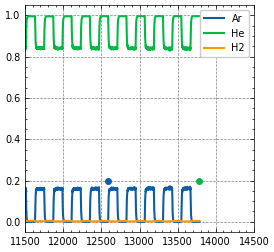

In [321]:
plt.plot(t_source, n_dot[:,0], label="Ar", color="C0")
plt.plot(t_source, n_dot[:,1], label="He", color="C1")
plt.plot(t_source, n_dot[:,2], label="H2", color="C2")
plt.xlim(11500, 14500)
#plt.xlim(0,300)
plt.scatter(t_offset, 0.2)
plt.scatter(t_source[-1], 0.2)

# plt.xlim(700,1000)
# plt.xlim(14*60, 16*60)
#plt.xlim(14.5*60,)
plt.legend()

In [322]:
print(time_delta.shape)
print(n_dot.shape)

(29044,)
(29044, 3)


In [323]:
interp = scipy.interpolate.interp1d(
    time_delta,
    n_dot.T,
    kind="linear",
    fill_value="extrapolate",
)

In [324]:
t = np.linspace(*t_range, 4810)
n_dot_interp = interp(t)

<>:5: SyntaxWarning: invalid escape sequence '\;'
<>:6: SyntaxWarning: invalid escape sequence '\;'
<>:5: SyntaxWarning: invalid escape sequence '\;'
<>:6: SyntaxWarning: invalid escape sequence '\;'
C:\Users\admin\AppData\Local\Temp\ipykernel_16452\1782322095.py:5: SyntaxWarning: invalid escape sequence '\;'
  xlabel="$t\;/\;\mathrm{s}$",
C:\Users\admin\AppData\Local\Temp\ipykernel_16452\1782322095.py:6: SyntaxWarning: invalid escape sequence '\;'
  ylabel="$x\;/\; 1$",


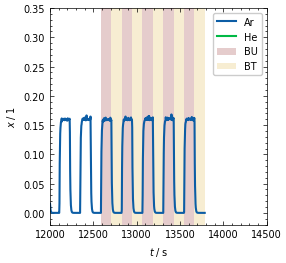

In [325]:
fig = plt.figure()
ax = ICIW_Plots.make_square_ax(
    fig=fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="$t\;/\;\mathrm{s}$",
    ylabel="$x\;/\; 1$",
    xlim=(12000, 14500),
    ylim=(-0.02, 0.35),
)
ax.grid(False)
plt.plot(t, n_dot_interp[0], label="Ar")
plt.plot(t, n_dot_interp[1], label="He")


for interval in intervals[::2]:
    plt.fill_betweenx(
        [-0.1, 0.4],
        interval[0],
        interval[1],
        alpha=0.2,
        color="maroon",
        edgecolor=None,
        zorder=-1,
        label="BU",
    )
for interval in intervals[1::2]:
    plt.fill_betweenx(
        [-0.1, 0.4],
        interval[0],
        interval[1],
        alpha=0.2,
        color="goldenrod",
        edgecolor=None,
        zorder=-1,
        label="BT",
    )
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys())
plt.savefig("exp_data_with_halfperiods.png", dpi=600)

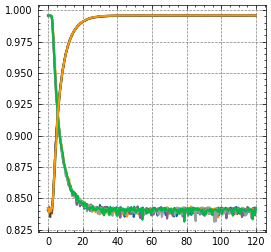

In [326]:
fig = plt.figure()
for interval in intervals:

    t = np.linspace(interval[0], interval[0] + 120, 480 + 1)

    n_dot_interp = interp(t)

    plt.plot(t - interval[0], n_dot_interp[1])

In [327]:
%pip install torch
%pip install lightning

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [328]:
import sys

sys.path.append(r"C:\Users\admin\Documents\GitHub\THA\lib")
from pathlib import Path
from nRTD.rtd_fitting import RTDDataModule

data_total_system = RTDDataModule(
    batch_size=32, # 10 half-periods, 2 temperature, 4 different capillary positions
    data_file=Path(
        r"C:\Users\admin\Documents\GitHub\THA\Experiments\THA_001\A_capillary_2barabs\nRTD_ptk_capillary_nocat_25°C_1bar_reactor63mlmin_matrix0mlmin.npz"),
    switching_times=switching_times,
    t_range_in=t_in,
    n_in=n_in,
    t_range_out=t_out,
    n_out=n_out,
    switch_delay=1.0,
)

In [329]:
data_total_system.setup("fit")
data_total_system.x[0]

tensor([[4.5427e-06, 4.5427e-06, 4.5427e-06, 4.5427e-06, 1.5933e-01, 1.5933e-01,
         1.5933e-01, 1.5933e-01, 1.5933e-01, 1.5933e-01, 1.5933e-01, 1.5933e-01,
         1.5933e-01, 1.5933e-01, 1.5933e-01, 1.5933e-01, 1.5933e-01, 1.5933e-01,
         1.5933e-01, 1.5933e-01, 1.5933e-01, 1.5933e-01, 1.5933e-01, 1.5933e-01,
         1.5933e-01, 1.5933e-01, 1.5933e-01, 1.5933e-01, 1.5933e-01, 1.5933e-01,
         1.5933e-01, 1.5933e-01, 1.5933e-01, 1.5933e-01, 1.5933e-01, 1.5933e-01,
         1.5933e-01, 1.5933e-01, 1.5933e-01, 1.5933e-01, 1.5933e-01, 1.5933e-01,
         1.5933e-01, 1.5933e-01, 1.5933e-01, 1.5933e-01, 1.5933e-01, 1.5933e-01,
         1.5933e-01, 1.5933e-01, 1.5933e-01, 1.5933e-01, 1.5933e-01, 1.5933e-01,
         1.5933e-01, 1.5933e-01, 1.5933e-01, 1.5933e-01, 1.5933e-01, 1.5933e-01,
         1.5933e-01, 1.5933e-01, 1.5933e-01, 1.5933e-01, 1.5933e-01, 1.5933e-01,
         1.5933e-01, 1.5933e-01, 1.5933e-01, 1.5933e-01, 1.5933e-01, 1.5933e-01,
         1.5933e-01, 1.5933e

In [330]:
print(data_total_system.x.shape) # 48 = 3 * 16, 3 components


torch.Size([20, 1, 341])


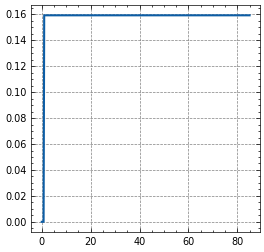

In [331]:
%matplotlib inline
plt.plot(data_total_system.t_in[0,:], data_total_system.x[0,0,:])
plt.show()
plt.close()

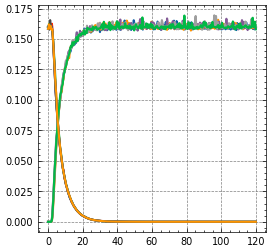

In [332]:
# plot t_in über x
%matplotlib inline
plt.figure()

for i in np.arange(0,20):
    if i %2==0:
        plt.plot(data_total_system.t_out[i, :], data_total_system.y[i, 0, ...], label="Ar")
plt.show()
plt.close()

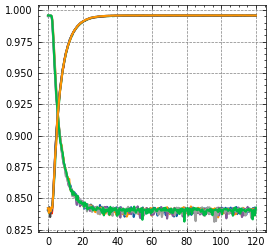

In [333]:
# plot t_in über x
%matplotlib inline
plt.figure()

for i in np.arange(0,20):
    if not i %2==0:
        plt.plot(data_total_system.t_out[i, :], data_total_system.y[i, 0, ...], label="He")
plt.show()
plt.close()

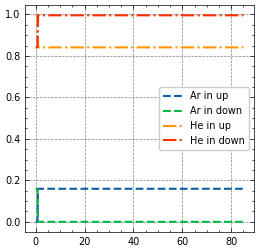

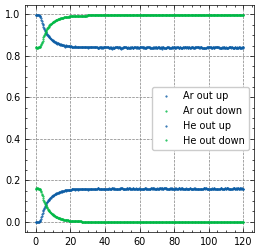

In [334]:
%matplotlib notebook
%matplotlib inline

fig = plt.figure()
index = 0
plt.plot(
    data_total_system.t_in[index],
    data_total_system.x[index].squeeze(),
    ls="--", label ='Ar in up'
)
plt.plot(
    data_total_system.t_in[index + 2],
    data_total_system.x[index + 2].squeeze(),
    ls="--", label = 'Ar in down'
)
plt.plot(
    data_total_system.t_in[index+1],
    data_total_system.x[index+1].squeeze(),
    ls="-.", label ='He in up'
)
plt.plot(
    data_total_system.t_in[index + 3],
    data_total_system.x[index + 3].squeeze(),
    ls="-.", label ='He in down'
)
plt.legend()
plt.show()


plt.plot(
    data_total_system.t_out[index],
    data_total_system.y[index].squeeze(),
    "o",
    c="C0",
    markersize=0.5, label ='Ar out up'
)
plt.plot(
    data_total_system.t_out[index + 2],
    data_total_system.y[index + 2].squeeze(),
    "o",
    c="C1",
    markersize=0.5, label ='Ar out down'
)
plt.plot(
    data_total_system.t_out[index+1],
    data_total_system.y[index+1].squeeze(),
    "o",
    c="C0",
    markersize=0.5, label ='He out up'
)
plt.plot(
    data_total_system.t_out[index + 3],
    data_total_system.y[index + 3].squeeze(),
    "o",
    c="C1",
    markersize=0.5, label ='He out down'
)
plt.legend()
plt.show()